# Momentum and Adam: gradients, state, and controlled evidence

## 1. Introduction and learning objectives

A gradient describes local sensitivity at one parameter snapshot. An optimizer turns current and past sensitivities into a parameter change; its state is part of the training computation. Two identical models can take different next steps when their optimizer histories differ. This distinction becomes essential when interpreting a training curve, accumulating token losses, changing a learning-rate schedule, or resuming a language-model run.

Derive gradient-buffer momentum and Adam; implement complete, nonmutating state transitions; independently verify a small network's derivatives; and compare algorithms with declared tuning and work budgets. Explain the limits of bias correction, clipping and scale invariance. Distinguish objective L2 from decoupled decay and verify an actual checkpoint round trip. A finite successful experiment supports a bounded observation, not a universal optimizer ranking or convergence theorem.

**Prerequisites:** Stage 00 expectation, finite differences and numerical arithmetic; Stage 01 gradient descent, regularization and evaluation; and the retained [backpropagation](backpropagation.ipynb) and [MLP](multilayer-perceptron.ipynb) chapters. [Multiclass objectives](multiclass-learning-objectives.ipynb) supplies the valid-token reduction connection. All implementations use NumPy; no earlier reference snippets are imported. Geometry, normalization and automatic differentiation receive separate subsequent units.

## 2. Prerequisites and mathematical foundations

Let parameters before update $t$ be $\theta_{t-1}$, with $t=1,2,\ldots$. A mini-batch gradient $g_t$ is evaluated at this **one unchanged snapshot**. A declared peak rate and an update-indexed schedule supply $\eta_t\geq0$. The reference accepts a dictionary of named, nonempty float64 vectors/matrices, at most 8 arrays and 8,192 elements. Gradient names and shapes must match exactly: broadcasting a bias gradient is an error. Every step requires every gradient; missing, explicitly zero and skipped updates are different operations.

For row-wise examples, the regression experiment uses
$$J(\theta)=\frac1n\sum_i\frac12(\hat y_i-y_i)^2+\frac{\lambda}{2}(\|W_1\|_F^2+\|W_2\|_F^2).$$
Biases are not penalized. This is half-MSE plus a weight penalty, not MSE and not a penalty divided by batch size. For uniform sampling with replacement, the batch mean data gradient plus $\lambda W$ estimates the full empirical objective gradient at a fixed snapshot. Changing the sampling distribution without correction changes that statement. A gradient of the empirical objective is also distinct from a gradient of unknown population risk.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 04.05.01 — Identify the state that determines a next step

**Type:** Conceptual · **Answer:** Markdown

Two runs have identical weights and see the same next batch. One uses freshly initialized Adam buffers; the other has completed 173 updates. Explain why their next parameter changes can differ. Name all information required to reproduce the continuation when the sampler and schedule are also stateful. Distinguish a zero gradient, zero learning rate, missing gradient and skipped update.

**Expected outcome:** separate model, optimizer, schedule, data/preprocessing and random state, with a precise update-clock convention.

**Your response to Exercise 04.05.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.01**

The bias-correction exponent is a counter of committed optimizer updates, not a count of observations or microbatches.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.01**

Adam needs its first and second raw-moment buffers and update counter as well as parameters. The next batch needs the sampler's generator state, not just its original seed. Continuation also needs algorithm/hyperparameters, schedule budget and position, objective normalization, decay masks, clipping order and the exact processed training data/order. This chapter samples with replacement, so there is no epoch cursor; a shuffled epoch iterator would need its permutation and cursor too. A zero gradient can leave historical momentum moving the parameters; zero rate leaves parameters fixed but still advances moments/counter here. A missing named gradient is rejected. A skipped call advances neither optimizer nor schedule. Later mixed-precision overflow handling must specify that policy explicitly. Weights alone are sufficient for some inference uses, but not exact training continuation.

</details>

## 3. Theoretical development and worked examples

### Momentum is a specified recurrence

Plain SGD uses $\theta_t=\theta_{t-1}-\eta_tg_t$. Our **unnormalized gradient-buffer momentum** is
$$u_t=\mu u_{t-1}+g_t,\quad u_0=0,\qquad\theta_t=\theta_{t-1}-\eta_tu_t,\quad0\leq\mu<1.$$
Expanding gives $u_t=\sum_{j=1}^t\mu^{t-j}g_j$. A persistent gradient $g$ approaches $g/(1-\mu)$; a single impulse fades geometrically. This is not the normalized exponential average $m_t=\mu m_{t-1}+(1-\mu)g_t$. If both start at zero, $m_t=(1-\mu)u_t$; the same numerical rate therefore does not make their steps equal.

[Sutskever et al. (2013), §2 equations (1)–(4)](https://proceedings.mlr.press/v28/sutskever13.pdf) use a displacement velocity $v_t=\mu v_{t-1}-\eta_tg_t$, $\theta_t=\theta_{t-1}+v_t$. With **constant** rate, $v_t=-\eta u_t$ maps the recurrences. When the rate changes, multiplying the complete gradient buffer by the new rate also rescales historical contributions, whereas displacement velocity retains their earlier rates. Declare which convention is implemented. Nesterov's look-ahead gradient is another distinct recurrence; it is not obtained simply by renaming this buffer.

On $f(\theta)=a\theta^2/2$ with constant rate and $a>0$, elimination of $u$ yields
$$\theta_t=(1+\mu-\eta a)\theta_{t-1}-\mu\theta_{t-2}.$$
The characteristic roots solve $r^2-(1+\mu-\eta a)r+\mu=0$. For $0\leq\mu<1$, they lie strictly inside the unit circle exactly when $0<\eta a<2(1+\mu)$. Complex roots give damped oscillations; stable need not mean monotone loss. This scalar quadratic calculation does not guarantee successful stochastic or nonconvex training. The next geometry chapter develops curvature beyond this bounded case.

### Exercise 04.05.02 — Expand momentum and justify its restricted stability claim

**Type:** Mathematical · **Answer:** Markdown

Derive the finite history sum, its persistent-gradient limit and the normalization conversion. Derive the second-order scalar-quadratic recurrence and use the quadratic stability inequalities $|\mu|<1$, $1-A+\mu>0$, $1+A+\mu>0$, where $A=1+\mu-\eta a$, to obtain the stated strict interval. Explain why changing the rate breaks the simple displacement mapping.

**Expected outcome:** correct history weights, rate scaling, boundary cases and assumptions, without a neural-network convergence claim.

**Your response to Exercise 04.05.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.02**

Substitute $u_{t-1}=(\theta_{t-2}-\theta_{t-1})/\eta$ only while the rate is constant and positive.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.02**

Repeated substitution yields a geometric sum; for constant $g$ it is $(1-\mu^t)g/(1-\mu)$. Multiplication by $1-\mu$ gives the normalized average. Substituting the previous displacement into the next update produces $A\theta_{t-1}-\mu\theta_{t-2}$. The stability inequalities reduce to $\eta a>0$ and $2(1+\mu)-\eta a>0$, with $\mu<1$. Equality leaves a unit-modulus root, so the bounds are strict. In several dimensions this applies separately to eigenmodes of a fixed positive-definite quadratic, requiring the bound for every eigenvalue. With varying rates the historical term in a displacement recurrence contains the old rate, while the gradient-buffer step uses the current rate on all history; a constant conversion no longer holds. Noise, changing curvature and nonconvexity require additional analysis.

</details>

### Adam tracks first and second raw moments

For zero initialization and $0\leq\beta_1,\beta_2<1$,
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t\odot g_t,$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\quad\hat v_t=\frac{v_t}{1-\beta_2^t},\qquad
\theta_t=\theta_{t-1}-\eta_t\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon},\quad\epsilon>0.$$
All products/divisions here are coordinatewise. $v$ estimates a **second raw moment**, not centered variance. The denominator adds epsilon **outside** the square root after correction. Moving it inside, or absorbing correction into the rate while leaving epsilon unchanged, changes the finite-epsilon update. The implementation uses $-\operatorname{expm1}(t\log\beta)$ for $1-\beta^t$ (and handles $\beta=0$ separately).

For time-independent expectations $E[g_j]=a$, $E[g_j^2]=b$, the geometric coefficients give $E[m_t]=(1-\beta_1^t)a$ and $E[v_t]=(1-\beta_2^t)b$. This expectation argument needs equal moments, not independence across all steps. Training gradients generally change distribution. Correction then produces a normalized history-weighted average, not the current moment in general. Even in the equal-moment case, the nonlinear ratio $\hat m/\sqrt{\hat v}$ is not an unbiased population-gradient estimator. [Kingma and Ba, v9, Algorithm 1 and §§2–3](https://arxiv.org/pdf/1412.6980v9) supply the precise recurrence and correction study.

### Exercise 04.05.03 — Compute two updates before writing an optimizer

**Type:** Numerical · **Answer:** Markdown

Start at $(1,-1)$ with zero state. Use $g_1=(2,-4)$ and $g_2=(-1,2)$. For gradient-buffer momentum with $\mu=.9$, rates $.1$ then $.025$, compute both buffers and final parameters; compare displacement momentum at those same rates. For Adam with $\beta_1=.9,\beta_2=.99$, compute both raw/corrected moments. State the finite-epsilon first step when $\epsilon=.01$ and rate $.1$.

**Expected outcome:** explicit state arithmetic demonstrating that conventions and epsilon placement matter.

**Your response to Exercise 04.05.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.03**

Adam's second update has correction divisors $.19$ and $.0199$. Squared gradients are nonnegative even when the first moment changes sign.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.03**

Gradient buffers are $(2,-4)$ and $(.8,-1.6)$, giving $(.8,-.6)$ then $(.78,-.56)$. Displacement velocities are $(-.2,.4)$ and $(-.155,.31)$, giving final $(.645,-.29)$. For Adam, $m_1=(.2,-.4)$, $v_1=(.04,.16)$; their corrected values are $(2,-4)$ and $(4,16)$. Next $m_2=(.08,-.16)$ and $v_2=(.0496,.1984)$; divide these by $.19$ and $.0199$, respectively. With epsilon $.01$, the first parameter change is $(-.2/2.01,+.4/4.01)$, so the first parameters are approximately $(.90049751,-.90024938)$. Ignoring correction or placing $.01$ inside the square root yields different values. The displacement and gradient-buffer disagreement is entirely explained by the rate change, not by random data.

</details>

### Exercise 04.05.04 — Derive what bias correction does and does not correct

**Type:** Mathematical · **Answer:** Markdown

Expand $m_t$ and $v_t$, derive their expectations when the first/second moments are constant, and write the expression when they vary with $j$. Show why the corrected second moment is not variance and why unbiased mini-batch gradients do not make an Adam update an unbiased full-batch Adam update.

**Expected outcome:** normalized geometric history weights, raw-moment terminology and a correctly restricted expectation claim.

**Your response to Exercise 04.05.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.04**

Expectation commutes with a weighted sum, but not generally with division by a random square root.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.04**

$m_t=(1-\beta_1)\sum_j\beta_1^{t-j}g_j$, with an analogous expression for squared gradients. Equal expectations factor out of the sum and leave $1-\beta^t$; otherwise the corrected expectation is a weighted sum of the separate $E[g_j]$ or $E[g_j^2]$. A variance additionally subtracts the square of a mean at a specified distribution; $v$ does not do that. With differing betas, even $\hat v-\hat m^2$ need not form a coherent finite-history variance estimator. Taking expectation of $m/\sqrt v$ is not division of the separate expectations. Thus initialization-bias correction does not remove sampling noise, parameter-distribution drift, nonlinear update bias, bad gradients or an inappropriate objective. No one of these identities proves convergence.

</details>

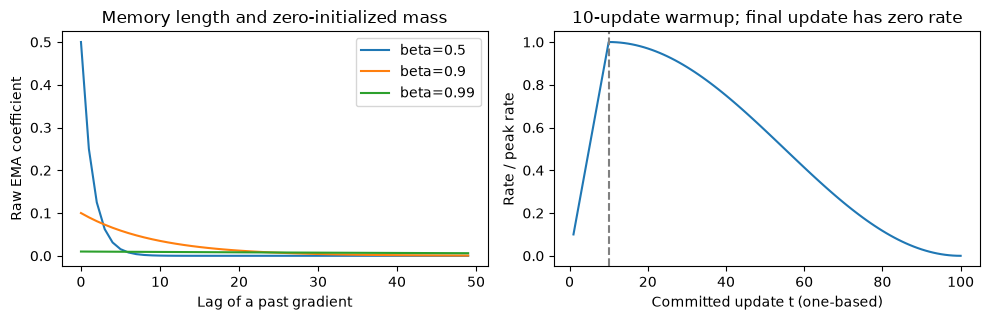

Finite 50-term EMA masses: {0.5: 0.9999999999999991, 0.9: 0.9948462247926799, 0.99: 0.3949939328624636}


In [2]:
# Analytic history weights and a declared schedule; no optimizer/trainer implementation.
lags = np.arange(50)
updates = np.arange(1, 101)
scheduled = np.where(updates <= 10, updates / 10,
                     .5 * (1 + np.cos(np.pi * (updates - 10) / 90)))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for beta in (.5, .9, .99):
    axes[0].plot(lags, (1 - beta) * beta ** lags, label=f"beta={beta}")
axes[0].set(xlabel="Lag of a past gradient", ylabel="Raw EMA coefficient",
            title="Memory length and zero-initialized mass")
axes[0].legend()
axes[1].plot(updates, scheduled)
axes[1].axvline(10, color="gray", linestyle="--")
axes[1].set(xlabel="Committed update t (one-based)", ylabel="Rate / peak rate",
            title="10-update warmup; final update has zero rate")
plt.tight_layout(); plt.show()
print("Finite 50-term EMA masses:", {b: float(np.sum((1-b)*b**lags)) for b in (.5, .9, .99)})

## 4. Guided exercises

### Declare numerical and state contracts first

The references copy inputs, reject nonfinite values, check complete named shapes and make a successful transition return new arrays/state. SGD has no moment arrays; momentum has a first buffer; Adam/AdamW have first/second buffers. A failed step returns no partial mutation. Finite gradients can still overflow when squared or combined: report the failure rather than silently clipping NaNs or accepting a nonfinite buffer. Optional **global** clipping forms $g'=c g$, $c=\min(1,C/\|g\|_2)$, before moment updates and after accumulation; $\|g\|$ includes all parameter arrays. This is different from coordinate clipping and can change the expected update direction.

### Exercise 04.05.05 — Specify bounded arrays, hyperparameters, norms and state

**Type:** Programming · **Answer:** Code

Implement contracts for the four algorithms, peak rate, betas, epsilon, optional global clipping, explicit AdamW decay names and bounded schedule/batch sizes. Require exact named gradient shapes, nonnegative Adam second buffers and zero buffers at counter zero. Compute the global norm using a scale to avoid unnecessary overflow. Return copies and reject unsupported ranges visibly.

**Expected outcome:** inspectable NumPy contracts with no accidental broadcasting, shared aliases or silent nonfinite state.

In [ ]:
# Your code for Exercise 04.05.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.05**

Normalize the arrays by their largest absolute entry before summing squared entries; the final norm itself can still exceed float64 range.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.05**

The following definitions are the shared dependencies for all later reference blocks. They bound this educational implementation, not a general optimizer library. Decay is restricted to AdamW and $\eta_{peak}\rho<1$. The latter keeps the declared shrink factor positive; other conventions are possible if deliberately derived. Schema checks establish admissible state, not proof that a supplied history is truthful.

~~~python
import copy
import hashlib
import json
import math
import time
from pathlib import Path
import tempfile


def opt_int(value, name, low, high):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or not low <= value <= high:
        raise ValueError(f"{name} must be an integer in [{low}, {high}]")
    return int(value)


def opt_real(value, name, low=0., strict=False):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise ValueError(f"{name} must be a finite real scalar")
    value = float(value)
    if not np.isfinite(value) or value < low or (strict and value == low):
        raise ValueError(f"invalid {name}")
    return value


def opt_arrays(values):
    if not isinstance(values, dict) or not 1 <= len(values) <= 8 or any(not isinstance(k, str) or not k for k in values):
        raise ValueError("use one to eight named parameter arrays")
    result = {}
    for key in sorted(values):
        raw = np.asarray(values[key])
        if raw.dtype.kind not in "iuf" or raw.ndim not in (1, 2) or not raw.size:
            raise ValueError("parameters/gradients are nonempty real vectors or matrices")
        array = np.array(raw, dtype=np.float64, copy=True)
        if not np.isfinite(array).all():
            raise ValueError("nonfinite array")
        result[key] = array
    if sum(value.size for value in result.values()) > 8192:
        raise ValueError("this teaching implementation caps total parameters at 8192")
    return result


def opt_same_arrays(values, parameters):
    result = opt_arrays(values)
    if result.keys() != parameters.keys() or any(result[k].shape != parameters[k].shape for k in parameters):
        raise ValueError("named shapes must match exactly; no gradient broadcasting")
    return result


def opt_norm(values):
    scale = max(float(np.max(np.abs(a))) for a in values.values())
    if scale == 0.:
        return 0.
    with np.errstate(over="raise", invalid="raise"):
        norm = scale * np.sqrt(sum(float(np.sum((a / scale) ** 2)) for a in values.values()))
    if not np.isfinite(norm):
        raise FloatingPointError("global norm exceeds float64 range")
    return float(norm)


def opt_config(kind="adam", rate=.01, momentum=.9, beta1=.9, beta2=.99,
               epsilon=1e-8, decay=0., decay_keys=(), clip=None,
               budget=600, warmup=20, batch=24):
    if kind not in ("sgd", "momentum", "adam", "adamw"):
        raise ValueError("unknown optimizer")
    rate = opt_real(rate, "rate", strict=True)
    momentum = opt_real(momentum, "momentum")
    beta1, beta2 = opt_real(beta1, "beta1"), opt_real(beta2, "beta2")
    if max(momentum, beta1, beta2) >= 1.:
        raise ValueError("decay factors must be below one")
    epsilon = opt_real(epsilon, "epsilon", strict=True)
    decay = opt_real(decay, "decay")
    if (kind != "adamw" and decay != 0.) or not np.isfinite(rate * decay) or rate * decay >= 1.:
        raise ValueError("decay is decoupled AdamW only, with rate * decay < 1")
    if not isinstance(decay_keys, (tuple, list)) or any(not isinstance(k, str) for k in decay_keys):
        raise ValueError("declare decay parameter names")
    if len(decay_keys) != len(set(decay_keys)):
        raise ValueError("duplicate decay names")
    if clip is not None:
        clip = opt_real(clip, "global clipping threshold", strict=True)
    budget = opt_int(budget, "budget", 2, 1000)
    warmup = opt_int(warmup, "warmup", 0, budget - 1)
    batch = opt_int(batch, "batch", 1, 256)
    return dict(kind=kind, rate=rate, momentum=momentum, beta1=beta1, beta2=beta2,
                epsilon=epsilon, decay=decay, decay_keys=list(decay_keys), clip=clip,
                budget=budget, warmup=warmup, batch=batch)


def opt_new_state(parameters, config):
    parameters, config = opt_arrays(parameters), opt_config(**config)
    if not set(config["decay_keys"]) <= parameters.keys() or (config["decay"] > 0 and not config["decay_keys"]):
        raise ValueError("decayed names must explicitly identify existing parameters")
    first = {} if config["kind"] == "sgd" else {k: np.zeros_like(v) for k, v in parameters.items()}
    second = {k: np.zeros_like(v) for k, v in parameters.items()} if config["kind"] in ("adam", "adamw") else {}
    return dict(t=0, first=first, second=second)


def opt_check_state(state, parameters, config):
    expected = opt_new_state(parameters, config)
    if not isinstance(state, dict) or state.keys() != expected.keys():
        raise ValueError("optimizer state schema")
    result = dict(t=opt_int(state["t"], "update counter", 0, config["budget"]))
    for name in ("first", "second"):
        if expected[name]:
            result[name] = opt_same_arrays(state[name], expected[name])
        else:
            if state[name] != {}:
                raise ValueError("unused optimizer buffers must be empty")
            result[name] = {}
    if any(np.any(v < 0) for v in result["second"].values()):
        raise ValueError("negative second raw moment")
    if result["t"] == 0 and any(np.any(v != 0) for name in ("first", "second") for v in result[name].values()):
        raise ValueError("fresh state starts at zero")
    return result
example_config = opt_config(kind="adam", budget=40, warmup=4)
example_parameters = {"w": np.array([1., -1.]), "b": np.zeros(1)}
print("Fresh buffers:", opt_new_state(example_parameters, example_config))
~~~

</details>

### Exercise 04.05.06 — Implement one complete optimizer transition

**Type:** Programming · **Answer:** Code

Using the previous contracts, implement plain SGD, the stated gradient-buffer momentum, corrected Adam and AdamW. Require a current rate in $[0,\eta_{peak}]$. Apply optional global clipping before moment updates. AdamW uses data-gradient moments and subtracts $\eta_t\rho M\theta_{t-1}$ using an explicit name mask $M$. Keep the old parameter snapshot for both terms. A zero-rate call still updates state/counter. Reject any failure without mutating caller arrays/state.

**Expected outcome:** a pure transition whose full state can be checked against hand and independent scalar calculations, including zero/large inputs.

In [ ]:
# Your code for Exercise 04.05.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.06**

Use raw buffers from the old state to calculate new buffers; use the new counter in both corrections. A missing gradient is not a zero array.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.06**

Depends on Exercise 04.05.05. This reference deliberately keeps algorithm state separate from network derivatives and the schedule. Underflow of tiny moment contributions can occur in float64; epsilon does not recover information already lost to rounding. Overflows or nonfinite results fail visibly. No gradients or parameters are modified in place.

~~~python
def opt_step(parameters, gradients, state, config, rate):
    """A pure, complete-parameter transition; missing gradients are an error."""
    parameters, config = opt_arrays(parameters), opt_config(**config)
    gradients = opt_same_arrays(gradients, parameters)
    state = opt_check_state(state, parameters, config)
    if state["t"] == config["budget"]:
        raise ValueError("update budget exhausted")
    rate = opt_real(rate, "current rate")
    if rate > config["rate"]:
        raise ValueError("current rate exceeds the declared peak")
    original_norm = opt_norm(gradients)
    factor = 1. if config["clip"] is None or original_norm == 0. else min(1., config["clip"] / original_norm)
    gradients = {k: value * factor for k, value in gradients.items()}
    next_state = copy.deepcopy(state)
    next_state["t"] += 1
    t, kind = next_state["t"], config["kind"]
    updated = {}
    with np.errstate(over="raise", invalid="raise", divide="raise"):
        for key, old in parameters.items():
            g = gradients[key]
            if kind == "sgd":
                direction = g
            elif kind == "momentum":
                buffer = config["momentum"] * state["first"][key] + g
                next_state["first"][key] = buffer
                direction = buffer
            else:
                b1, b2 = config["beta1"], config["beta2"]
                first = b1 * state["first"][key] + (1 - b1) * g
                second = b2 * state["second"][key] + (1 - b2) * g ** 2
                next_state["first"][key], next_state["second"][key] = first, second
                correction1 = 1. if b1 == 0. else -math.expm1(t * math.log(b1))
                correction2 = 1. if b2 == 0. else -math.expm1(t * math.log(b2))
                direction = (first / correction1) / (np.sqrt(second / correction2) + config["epsilon"])
            candidate = old - rate * direction
            if kind == "adamw" and config["decay"] and key in config["decay_keys"]:
                candidate = candidate - rate * config["decay"] * old
            if not np.isfinite(candidate).all() or not np.isfinite(direction).all():
                raise FloatingPointError("nonfinite optimizer transition")
            updated[key] = candidate
    # This also rejects nonfinite moments even if an otherwise finite parameter hides them.
    opt_check_state(next_state, updated, config)
    return updated, next_state, dict(original_gradient_norm=original_norm,
                                    applied_gradient_norm=opt_norm(gradients),
                                    update_norm=opt_norm({k: updated[k] - parameters[k] for k in parameters}))
hand_config = opt_config(kind="adam", rate=.1, epsilon=.01, budget=4, warmup=0)
hand_parameters = {"w": np.array([1., -1.])}
hand_state = opt_new_state(hand_parameters, hand_config)
for hand_gradient in ([2., -4.], [-1., 2.]):
    hand_parameters, hand_state, hand_stats = opt_step(hand_parameters, {"w": np.array(hand_gradient)}, hand_state, hand_config, .1)
    print("Counter/parameters/moments:", hand_state["t"], hand_parameters, hand_state["first"], hand_state["second"])
~~~

</details>

### Scale, clock and finite epsilon

For a prescribed gradient sequence multiplied by positive $c$, zero-initialized Adam has $m'=cm$, $v'=c^2v$. If epsilon were zero and denominators nonzero, the normalized direction is unchanged. With positive epsilon, the scaled direction equals $\hat m/(\sqrt{\hat v}+\epsilon/c)$, so invariance is approximate only when epsilon is negligible. A nonlinear model's later gradients also depend on its changed trajectory; scaling data loss while leaving L2 unchanged is not scaling the complete gradient sequence. An adaptive denominator is neither a Hessian inverse nor a confidence interval.

### Exercise 04.05.07 — Explain zero updates, scaling and the role of epsilon

**Type:** Conceptual · **Answer:** Markdown

Explain why zero gradients can still move momentum/Adam, why a zero-rate call still changes a future step, and why skipped calls are different. Derive the epsilon dependence under positive gradient scaling. Does this establish invariance to a change of parameter coordinates or to scaling only the data term of a regularized objective?

**Expected outcome:** correct history/clock behavior and a restricted scale statement, with no claim that Adam is curvature-aware Newton optimization.

**Your response to Exercise 04.05.07**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.07**

Set the current gradient to zero after a nonzero history. Separately multiply every historical gradient by $c$ before simplifying the normalized direction.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.07**

Historical first buffers decay but generally remain nonzero when the current gradient is zero, so their next direction can move parameters. A zero rate produces zero displacement but still changes both buffers and the correction counter here. A skipped call changes neither. Scaling the complete prescribed gradient history gives an effective epsilon $\epsilon/c$ after cancellation, not exact invariance at fixed positive epsilon. A parameter reparameterization also changes how a coordinatewise step maps back to the original space; this algebra does not establish reparameterization invariance. Scaling only data loss leaves a weight penalty gradient unchanged and does not give $g'=cg$. The stored squared gradients are not second derivatives and do not justify a Newton or uncertainty interpretation.

</details>

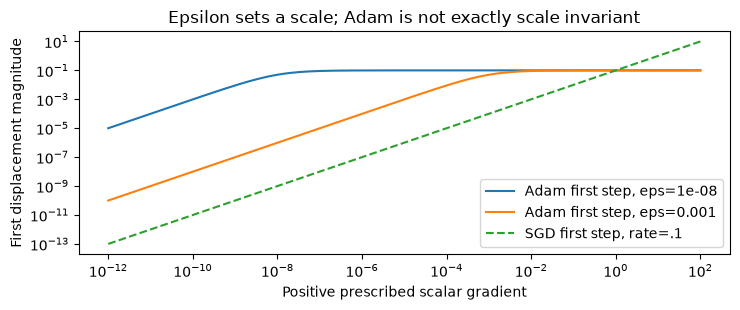

In [3]:
# Closed-form first-step response, not an implementation of the recurrent algorithm.
magnitudes = np.logspace(-12, 2, 200)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for epsilon in (1e-8, 1e-3):
    ax.loglog(magnitudes, .1 * magnitudes / (magnitudes + epsilon), label=f"Adam first step, eps={epsilon:g}")
ax.loglog(magnitudes, .1 * magnitudes, "--", label="SGD first step, rate=.1")
ax.set(xlabel="Positive prescribed scalar gradient", ylabel="First displacement magnitude",
       title="Epsilon sets a scale; Adam is not exactly scale invariant")
ax.legend(); plt.tight_layout(); plt.show()

### Accumulation changes the effective update clock

Suppose microbatch $j$ reports a **mean** data gradient $g_j$ with positive mass $a_j$ (row count, or valid-token count under a token-mean objective). At fixed parameters the union gradient is $\sum_j a_jg_j/\sum_j a_j$. A mean of means is valid only for equal masses. Add a shared L2 gradient once after combining data gradients, or include it in every mean and combine with normalized coefficients; do not sum the penalty repeatedly. Clip the aggregate once if that is the declared large-batch algorithm. Do **one** optimizer transition and schedule advance for the union. Multiple Adam/momentum updates generally do not equal this operation, even for a prescribed gradient sequence. Stateful normalization and stochastic layers later add further conditions to large-batch equivalence.

The schedule here is one-based with total budget $B\geq2$ and $0\leq W<B$ warmup updates. For $W>0$, $\eta_t=\eta_{peak}t/W$ when $t\leq W$, then cosine progress $(t-W)/(B-W)$. For $W=0$, cosine progress is $(t-1)/(B-1)$. The cosine multiplier is $(1+\cos(\pi p))/2$. The final update has rate zero **and still consumes one update**. Never change $B$ during a claimed exact continuation; that changes earlier/future rates.

### Exercise 04.05.08 — Implement weighted accumulation and an explicit schedule

**Type:** Programming · **Answer:** Code

Implement the stated schedule, including no warmup, $W=B-1$, first/last updates and invalid counters. Combine one to sixteen named microbatch means using finite nonnegative masses with a positive total; support an ignored zero-mass batch with finite arrays, and reject all-zero mass. Normalize masses safely when their raw total would overflow. Explain where clipping and the optimizer step belong.

**Expected outcome:** correct unequal-mass arithmetic, explicit update boundaries and no automatic per-microbatch optimizer calls.

In [ ]:
# Your code for Exercise 04.05.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.08**

Divide masses by their maximum before normalizing. Do not use a training-example count as Adam's correction exponent.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.08**

Depends on the contracts from Exercise 04.05.05. Only finite arrays are accepted even for zero-mass placeholders; an all-masked mean is undefined. A positive relative mass that rounds to zero is rejected explicitly. These functions combine gradients at one parameter snapshot; they do not make already-applied updates commute. The example's union mean is $(1\cdot2+3\cdot(-2))/4=-1$, not the unweighted value zero.

~~~python
def opt_rate(config, update):
    config = opt_config(**config)
    t = opt_int(update, "one-based update", 1, config["budget"])
    peak, warmup, budget = config["rate"], config["warmup"], config["budget"]
    if warmup and t <= warmup:
        return peak * t / warmup
    progress = (t - warmup) / (budget - warmup) if warmup else (t - 1) / (budget - 1)
    return peak * .5 * (1 + math.cos(math.pi * progress))


def opt_accumulate(gradients, masses):
    if not isinstance(gradients, (tuple, list)) or not 1 <= len(gradients) <= 16:
        raise ValueError("one to sixteen microbatches")
    raw = np.asarray(masses)
    if raw.dtype.kind not in "iuf" or raw.shape != (len(gradients),):
        raise ValueError("one real mass per microbatch")
    masses = raw.astype(float)
    if not np.isfinite(masses).all() or np.any(masses < 0) or not np.any(masses > 0):
        raise ValueError("finite nonnegative masses with a positive total")
    normalized = masses / masses.max()
    normalized = normalized / normalized.sum()
    if np.any((masses > 0) & (normalized == 0)):
        raise FloatingPointError("positive relative mass is outside float64 range")
    template = opt_arrays(gradients[0])
    checked = [opt_same_arrays(g, template) for g in gradients]
    with np.errstate(over="raise", invalid="raise"):
        result = {k: sum(a * g[k] for a, g in zip(normalized, checked)) for k in template}
    return opt_same_arrays(result, template)
print("Weighted union gradient:", opt_accumulate([{"w": np.array([2.])}, {"w": np.array([-2.])}], [1, 3]))
schedule_config = opt_config(rate=.1, budget=100, warmup=10)
print("Schedule at updates 1,10,11,100:", [opt_rate(schedule_config, t) for t in (1, 10, 11, 100)])
~~~

</details>

### Objective regularization and decoupled decay

An L2-regularized objective supplies $g_{data}+\lambda M\theta$ **before** momentum/adaptation. Our AdamW instead updates moments from $g_{data}$ and uses
$$\theta_t=\theta_{t-1}-\eta_t\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}-\eta_t\rho M\theta_{t-1}.$$
For plain SGD, the same $\rho=\lambda$ makes this equal the objective-gradient step under this **rate-scaled decay convention**. With momentum or adaptive history the general equivalence fails. The original AdamW paper's Algorithm 2 writes $\eta_t^{paper}(\alpha d+\lambda_{paper}\theta)$; our $\eta_t=\eta_t^{paper}\alpha$ and $\rho=\lambda_{paper}/\alpha$. Explicitly map symbols instead of assuming every API's `weight_decay` means the same recurrence. In zero-gradient decay alone, a coordinate shrinks by $\prod_t(1-\eta_t\rho)$, so budget and schedule influence total shrinkage. This chapter does not interpret AdamW as descending the same fixed isotropic L2 objective as coupled Adam.

### Exercise 04.05.09 — Separate L2, AdamW and schedule-dependent shrinkage

**Type:** Numerical · **Answer:** Markdown

At $(1,2)$, zero data gradient, fresh state, rate $.1$ and coefficient $.1$, compare a coupled L2 first Adam step (epsilon $10^{-8}$) with a masked AdamW step. Compare plain SGD under the two conventions. Derive the accumulated shrinkage when the data direction is zero and explain the role of a bias-excluding mask.

**Expected outcome:** explicit different Adam parameters, exact plain-SGD equivalence in the declared convention, and a schedule product rather than a universal regularization claim.

**Your response to Exercise 04.05.09**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.09**

Coupled Adam sees gradients $(.1,.2)$ in both moment buffers; fresh AdamW sees zero data moments and only the decay displacement.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.09**

Coupled Adam yields approximately $(.90000001,1.900000005)$; AdamW yields exactly $(.99,1.98)$ up to floating arithmetic. Plain SGD with an L2 gradient also yields $(.99,1.98)$, matching direct rate-scaled decay. With no data direction, repeated masked coordinates receive the stated product, while unmasked biases do not shrink. A nonzero historical first moment invalidates the premise that the adaptive data direction is zero just because today's gradient is zero. Coefficient names, masks, epsilon placement and schedule must accompany a comparison. [Loshchilov and Hutter, v3, §2 and Algorithm 2](https://arxiv.org/pdf/1711.05101v3) motivate decoupling; their image-classification results are not reproduced by this hand calculation.

</details>

## 5. Implementation challenges

### A small network with independent derivative evidence

Use $H=\tanh(XW_1+b_1)$, $\hat y=(HW_2+b_2)_{:,0}$, with $W_1:(d,h)$, $b_1:(h,)$, $W_2:(h,1)$ and $b_2:(1,)$. The output sensitivity $D=(\hat y-y)_{:,None}/n$ includes the average **once**. Let $U=(DW_2^T)\odot(1-H^2)$. Weight gradients are $H^TD+\lambda W_2$ and $X^TU+\lambda W_1$; bias gradients sum $D$ and $U$. Every derivative uses the old weights. Derivative correctness is checked independently of optimizer correctness: a working state transition can optimize a wrongly scaled gradient just as consistently.

### Exercise 04.05.10 — Derive, implement and independently audit the regression network

**Type:** Programming · **Answer:** Code

Implement bounded forward evaluation and manual parameter gradients for the stated half-MSE/weight-only-L2 objective. Reject nonfinite hidden preactivations before tanh can hide them. Write a separate scalar-loop objective and central-difference audit of every weight and bias; it must not call the vector forward, vector gradient or optimizer. Declare a step and absolute tolerance and inspect small/large step sensitivity.

**Expected outcome:** correct shapes, a single observation normalization, a genuinely independent objective and explicit numerical error evidence.

In [ ]:
# Your code for Exercise 04.05.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.10**

For the independent definition, compute each hidden scalar with Python sums/math.tanh and accumulate each residual separately.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.10**

Depends on the contracts in Exercise 04.05.05. The auditor perturbs private parameter copies at $\delta=10^{-5}$ and compares the independent scalar definition. The displayed assertion uses maximum absolute error $10^{-7}$, appropriate to this tiny moderate-scale fixture; relative error near a zero derivative can be misleading. Passing the fixture is evidence for the checked computation, not all possible states. The full test suite checks additional batch sizes, L2 coefficients, seeds and row replication independently.

~~~python
def opt_training_arrays(X, y):
    raw_x, raw_y = np.asarray(X), np.asarray(y)
    if raw_x.dtype.kind not in "iuf" or raw_y.dtype.kind not in "iuf":
        raise ValueError("real training arrays")
    X, y = np.array(raw_x, dtype=float, copy=True), np.array(raw_y, dtype=float, copy=True)
    if X.ndim != 2 or not 1 <= len(X) <= 2048 or not 1 <= X.shape[1] <= 8 or y.shape != (len(X),):
        raise ValueError("X:(n,d), y:(n,), bounded nonempty observations")
    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError("finite training arrays")
    return X, y


def opt_forward(parameters, X, y, l2=0.):
    parameters, (X, y) = opt_arrays(parameters), opt_training_arrays(X, y)
    l2 = opt_real(l2, "L2 coefficient")
    if set(parameters) != {"W1", "b1", "W2", "b2"}:
        raise ValueError("one-hidden-layer regression parameter names")
    h = parameters["b1"].size
    if not 1 <= h <= 32 or parameters["W1"].shape != (X.shape[1], h) or parameters["b1"].shape != (h,) or parameters["W2"].shape != (h, 1) or parameters["b2"].shape != (1,):
        raise ValueError("network shapes; one-dimensional biases")
    with np.errstate(over="raise", invalid="raise"):
        preactivation = X @ parameters["W1"] + parameters["b1"]
        if not np.isfinite(preactivation).all():
            raise FloatingPointError("nonfinite hidden preactivation")
        hidden = np.tanh(preactivation)
        prediction = (hidden @ parameters["W2"] + parameters["b2"])[:, 0]
        residual = prediction - y
        loss = float(np.mean(residual ** 2) / 2)
        if l2:
            loss += l2 * sum(float(np.sum(parameters[k] ** 2)) for k in ("W1", "W2")) / 2
    if not np.isfinite(loss):
        raise FloatingPointError("nonfinite half-MSE objective")
    return loss, prediction, hidden, residual, parameters, X


def opt_mlp(parameters, X, y, l2=0.):
    loss, prediction, hidden, residual, parameters, X = opt_forward(parameters, X, y, l2)
    with np.errstate(over="raise", invalid="raise"):
        output = residual[:, None] / len(X)
        upstream = (output @ parameters["W2"].T) * (1 - hidden ** 2)
        gradients = dict(W2=hidden.T @ output, b2=output.sum(axis=0),
                         W1=X.T @ upstream, b1=upstream.sum(axis=0))
        if l2:
            for key in ("W1", "W2"):
                gradients[key] += l2 * parameters[key]
    return loss, opt_same_arrays(gradients, parameters), prediction


def opt_initial(d, hidden=8, seed=40501):
    d, hidden = opt_int(d, "input width", 1, 8), opt_int(hidden, "hidden width", 1, 32)
    rng = np.random.default_rng(opt_int(seed, "initialization seed", 0, 2**32 - 1))
    return dict(W1=rng.normal(size=(d, hidden)) / np.sqrt(d), b1=np.zeros(hidden),
                W2=rng.normal(size=(hidden, 1)) / np.sqrt(hidden), b2=np.zeros(1))


def opt_scalar_objective(parameters, X, y, l2):
    """An independent scalar-loop definition, not the vector forward/gradient."""
    total = 0.
    for row, target in zip(X, y):
        hidden = [math.tanh(sum(float(a) * float(w) for a, w in zip(row, column)) + float(b))
                  for column, b in zip(parameters["W1"].T, parameters["b1"])]
        prediction = sum(a * float(w) for a, w in zip(hidden, parameters["W2"][:, 0])) + float(parameters["b2"][0])
        total += (prediction - float(target)) ** 2 / (2 * len(X))
    return total + l2 * sum(float(v) ** 2 for k in ("W1", "W2") for v in parameters[k].ravel()) / 2


def opt_audit(parameters, X, y, l2=.02, delta=1e-5):
    parameters = opt_arrays(parameters)
    delta = opt_real(delta, "finite-difference step", strict=True)
    loss, gradients, _ = opt_mlp(parameters, X, y, l2)
    errors = {}
    for key in parameters:
        independent = np.empty_like(parameters[key])
        for coordinate in np.ndindex(parameters[key].shape):
            plus, minus = copy.deepcopy(parameters), copy.deepcopy(parameters)
            plus[key][coordinate] += delta
            minus[key][coordinate] -= delta
            independent[coordinate] = (opt_scalar_objective(plus, X, y, l2) - opt_scalar_objective(minus, X, y, l2)) / (2 * delta)
        errors[key] = float(np.max(np.abs(gradients[key] - independent)))
    return dict(loss_difference=abs(loss - opt_scalar_objective(parameters, X, y, l2)), maximum_absolute_errors=errors)
audit_x = np.array([[-.7, .2], [.3, -.5], [.8, .4]])
audit_y = np.array([.4, -.2, .7])
audit_report = opt_audit(opt_initial(2, hidden=3, seed=40501), audit_x, audit_y)
print("Independent derivative audit:", audit_report)
assert audit_report["loss_difference"] < 1e-12
assert max(audit_report["maximum_absolute_errors"].values()) < 1e-7
for audit_delta in (1e-2, 1e-5, 1e-8):
    sensitivity = opt_audit(opt_initial(2, hidden=3, seed=40501), audit_x, audit_y, delta=audit_delta)
    print("Step-size sensitivity, delta / max error:", audit_delta, max(sensitivity["maximum_absolute_errors"].values()))
~~~

</details>

### Exercise 04.05.11 — Build a sampler-aware, resumable training computation

**Type:** Programming · **Answer:** Code

Represent the network, optimizer, immutable schedule configuration, objective coefficient, exact processed-training fingerprint, sampler state, seeds and trace explicitly. Use uniform row sampling with replacement; no global NumPy seed. A continuation gets an additional update count, never resets its budget, and returns private updated state. Log every batch objective, norm, update norm and rate; evaluate the full training objective only every 20 updates and at budget end. Preserve the old run on failure.

**Expected outcome:** a complete bounded training state with deterministic update/sample accounting and no answer-cell dependencies.

In [ ]:
# Your code for Exercise 04.05.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.11**

A checkpoint at update 173 must resume at update 174, using the generator's cached state and the original total schedule budget.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.11**

Depends on Exercises 04.05.05–06, 08 and 10. Each call restores a private PCG64 generator. The processed arrays are supplied separately and checked by shape/content/order fingerprint; the checkpoint does not contain or recreate the dataset. A deployment pipeline would additionally package its preprocessing and vocabulary artifacts. Full-objective monitoring is tied to global update indices, so splitting a call at an arbitrary update does not add a different monitoring point. Batch objectives are measured **before** their update and full-objective monitors after it; curves must respect that distinction. Counter/config/finite trace checks do not establish that a deliberately edited finite history is truthful.

~~~python
def opt_fingerprint(X, y):
    X, y = opt_training_arrays(X, y)
    h = hashlib.sha256(str((X.shape, y.shape, "float64-C")).encode())
    h.update(X.tobytes(order="C")); h.update(y.tobytes(order="C"))
    return h.hexdigest()


def opt_make_run(X, y, config, initial_seed=40501, batch_seed=40601, hidden=8, l2=.002):
    X, y = opt_training_arrays(X, y)
    config = opt_config(**config)
    l2 = opt_real(l2, "L2 coefficient")
    if config["kind"] == "adamw" and l2 != 0.:
        raise ValueError("this comparison keeps AdamW data gradients separate from L2")
    parameters = opt_initial(X.shape[1], hidden, initial_seed)
    batch_seed = opt_int(batch_seed, "batch seed", 0, 2**32 - 1)
    rng = np.random.default_rng(batch_seed)
    return dict(version=1, config=config, parameters=parameters,
                optimizer=opt_new_state(parameters, config), random=copy.deepcopy(rng.bit_generator.state),
                train_hash=opt_fingerprint(X, y), initial_seed=int(initial_seed), batch_seed=batch_seed,
                l2=l2, initial_objective=opt_forward(parameters, X, y, l2)[0], trace=[])


def opt_check_run(run, X, y):
    required = {"version", "config", "parameters", "optimizer", "random", "train_hash", "initial_seed", "batch_seed", "l2", "initial_objective", "trace"}
    if not isinstance(run, dict) or run.keys() != required or type(run["version"]) is not int or run["version"] != 1:
        raise ValueError("training-state schema/version")
    result = copy.deepcopy(run)
    result["config"] = opt_config(**run["config"])
    result["parameters"] = opt_arrays(run["parameters"])
    result["optimizer"] = opt_check_state(run["optimizer"], result["parameters"], result["config"])
    if run["train_hash"] != opt_fingerprint(X, y):
        raise ValueError("training values/order/preprocessing changed")
    result["initial_seed"] = opt_int(run["initial_seed"], "initial seed", 0, 2**32 - 1)
    result["batch_seed"] = opt_int(run["batch_seed"], "batch seed", 0, 2**32 - 1)
    result["l2"] = opt_real(run["l2"], "L2 coefficient")
    result["initial_objective"] = opt_real(run["initial_objective"], "initial objective")
    if result["config"]["kind"] == "adamw" and result["l2"] != 0.:
        raise ValueError("AdamW uses data gradients in this trainer")
    opt_forward(result["parameters"], X, y, result["l2"])
    if not isinstance(run["random"], dict) or run["random"].get("bit_generator") != "PCG64":
        raise ValueError("restore the declared PCG64 sampler")
    random = run["random"]
    if random.keys() != {"bit_generator", "state", "has_uint32", "uinteger"} or not isinstance(random["state"], dict) or random["state"].keys() != {"state", "inc"}:
        raise ValueError("PCG64 state schema")
    for name in ("state", "inc"):
        opt_int(random["state"][name], "PCG64 128-bit state", 0, 2**128 - 1)
    opt_int(random["has_uint32"], "PCG64 cached-word flag", 0, 1)
    opt_int(random["uinteger"], "PCG64 cached word", 0, 2**32 - 1)
    rng = np.random.Generator(np.random.PCG64())
    try:
        rng.bit_generator.state = copy.deepcopy(run["random"])
    except (ValueError, TypeError, KeyError, OverflowError) as error:
        raise ValueError("invalid sampler state") from error
    if not isinstance(run["trace"], list) or len(run["trace"]) != result["optimizer"]["t"]:
        raise ValueError("one trace entry per committed update")
    fields = {"t", "rate", "batch_objective", "gradient_norm", "applied_gradient_norm", "update_norm", "full_objective"}
    for t, row in enumerate(run["trace"], 1):
        if not isinstance(row, dict) or row.keys() != fields:
            raise ValueError("trace schema/order")
        opt_int(row["t"], "trace update", t, t)
        if row["rate"] != opt_rate(result["config"], t):
            raise ValueError("schedule and update clock disagree")
        for key in fields - {"t", "full_objective"}:
            opt_real(row[key], key)
        expected_full = t % 20 == 0 or t == result["config"]["budget"]
        if expected_full:
            opt_real(row["full_objective"], "full objective")
        elif row["full_objective"] is not None:
            raise ValueError("full-objective monitoring uses the declared update grid")
    return result, rng


def opt_continue(run, X, y, updates):
    X, y = opt_training_arrays(X, y)
    result, rng = opt_check_run(run, X, y)
    config = result["config"]
    remaining = config["budget"] - result["optimizer"]["t"]
    updates = opt_int(updates, "additional updates", 0, remaining)
    for _ in range(updates):
        t = result["optimizer"]["t"] + 1
        indices = rng.integers(0, len(X), size=config["batch"])
        loss, gradients, _ = opt_mlp(result["parameters"], X[indices], y[indices], result["l2"])
        rate = opt_rate(config, t)
        parameters, state, diagnostics = opt_step(result["parameters"], gradients, result["optimizer"], config, rate)
        result["parameters"], result["optimizer"] = parameters, state
        full = opt_forward(parameters, X, y, result["l2"])[0] if t % 20 == 0 or t == config["budget"] else None
        result["trace"].append(dict(t=t, rate=rate, batch_objective=loss,
                                   gradient_norm=diagnostics["original_gradient_norm"],
                                   applied_gradient_norm=diagnostics["applied_gradient_norm"],
                                   update_norm=diagnostics["update_norm"], full_objective=full))
    result["random"] = copy.deepcopy(rng.bit_generator.state)
    return result
training_config = opt_config(kind="momentum", rate=.008, budget=40, warmup=4)
short_run = opt_make_run(audit_x, audit_y, training_config, hidden=3)
short_run = opt_continue(short_run, audit_x, audit_y, 13)
print("Partial counter and last logged batch:", short_run["optimizer"]["t"], short_run["trace"][-1])
~~~

</details>

### Exercise 04.05.12 — Save and validate a real checkpoint without executable serialization

**Type:** Programming · **Answer:** Code

Encode the complete small run as bounded JSON bytes containing numeric lists, PCG64 state and schema/version metadata. Include a content checksum, reject nonfinite JSON constants, and validate named shapes, counters, trace order/schedule and the training fingerprint on reload. Use a temporary file for the round trip. Explain what the checksum does not establish.

**Expected outcome:** an inspectable, non-pickle checkpoint that actually resumes; explicit same-environment and external-data assumptions.

In [ ]:
# Your code for Exercise 04.05.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.12**

JSON round-trips these float64 Python values; convert numeric array lists back through the same shape/finite contracts before training.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.12**

Depends on the preceding training block. The two-MiB limit is a teaching bound, not a format for large models. The checksum detects accidental content changes; it is not an authenticated signature, a guarantee of mathematical correctness or a safe way to trust arbitrary metadata. No dynamic code is loaded. These tests target checkpoints produced by this notebook. Exact bitwise continuation is demonstrated on the same NumPy/BLAS/platform; another environment may change arithmetic even with the same seed. An epoch-shuffle sampler, dropout, device RNG, loss scaler or distributed sampler would require additional state when introduced.

~~~python
def opt_plain(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, dict):
        return {key: opt_plain(item) for key, item in value.items()}
    if isinstance(value, (tuple, list)):
        return [opt_plain(item) for item in value]
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    return value


def opt_json_bytes(value):
    return json.dumps(opt_plain(value), sort_keys=True, separators=(",", ":"), allow_nan=False).encode("utf-8")


def opt_dump(run, X, y):
    checked, _ = opt_check_run(run, X, y)
    payload = opt_plain(checked)
    envelope = dict(format="mlfs-optimizer-json-1", sha256=hashlib.sha256(opt_json_bytes(payload)).hexdigest(), payload=payload)
    encoded = opt_json_bytes(envelope)
    if len(encoded) > 2 * 1024**2:
        raise ValueError("checkpoint exceeds the two MiB teaching limit")
    return encoded


def opt_reject_constant(value):
    raise ValueError(f"nonfinite JSON constant {value}")


def opt_load(encoded, X, y):
    if not isinstance(encoded, bytes) or not 1 <= len(encoded) <= 2 * 1024**2:
        raise ValueError("bounded checkpoint bytes required")
    envelope = json.loads(encoded.decode("utf-8"), parse_constant=opt_reject_constant)
    if not isinstance(envelope, dict) or envelope.keys() != {"format", "sha256", "payload"} or envelope["format"] != "mlfs-optimizer-json-1":
        raise ValueError("checkpoint envelope")
    if envelope["sha256"] != hashlib.sha256(opt_json_bytes(envelope["payload"])).hexdigest():
        raise ValueError("checkpoint content checksum mismatch")
    checked, _ = opt_check_run(envelope["payload"], X, y)
    return checked
with tempfile.TemporaryDirectory(prefix="mlfs-optimizer-") as checkpoint_directory:
    checkpoint_path = Path(checkpoint_directory) / "training.json"
    checkpoint_path.write_bytes(opt_dump(short_run, audit_x, audit_y))
    restored_short = opt_load(checkpoint_path.read_bytes(), audit_x, audit_y)
    print("Temporary checkpoint bytes / restored counter:", checkpoint_path.stat().st_size, restored_short["optimizer"]["t"])
assert opt_dump(short_run, audit_x, audit_y) == opt_dump(restored_short, audit_x, audit_y)
~~~

</details>

## 6. Experiments and visualizations

### A declared comparison, including its boundaries

Generate independent train/validation/final streams from SeedSequence(40500), with 192/96/192 observations and two correlated features. For each observation, $x_1\sim U[-2,2]$, $x_2=.9x_1+.3e$, and $y=\sin(1.7x_1)+.35x_2^2+.2x_1x_2+.12z$, with independent standard-normal $e,z$. Fit means and population-standard-deviation scales on training rows only. The eight-unit tanh network has 33 parameters and a weight-only L2 coefficient $.002$.

The primary comparison is **SGD, gradient-buffer momentum, and coupled Adam on the same objective**. AdamW's different regularization rule is investigated separately, not silently included as an identical-objective contender. Declare three rates each: SGD $(.01,.04,.12)$, momentum $(.002,.008,.024)$, Adam $(.003,.01,.03)$. Momentum is $.9$; Adam uses $(.9,.99)$ and epsilon $10^{-8}$. Each rate uses the same three paired initialization seeds 40501–40503, with sampler seeds initialization+100. All use 600 updates, batch size 24 with replacement, 20-update warmup/cosine decay, and no clipping: **27 runs / 16,200 training updates / 388,800 sampled row occurrences**. Monitoring forward passes add work and are included in measured runtime; equal updates do not mean equal FLOPs, wall time or optimal tuning.

Choose a rate **within each algorithm** by mean validation half-MSE across all three seeds. Do not select a favorable seed. The displayed first minimum resolves a tie. The overall validation choice uses those three group means. Retain every candidate, failed attempt, trace, rate boundary and final full-gradient norm; fixed budget is not declared convergence. A failed numerical attempt is retained with unknown completed-prefix count because the transactional trainer returns no partial run; its group is ineligible. Do not claim it completed 600 updates.

Freeze choices before a single final panel evaluates all nine selected-rate/seed models and a training-mean baseline. Cache predictions; the in-memory final guard is consumed before inference, including if it fails, and cannot enforce behavior across a kernel restart. The published synthetic fixtures and author-visible results are instructional, not a blinded benchmark. For an independent study, preregister settings and use a fresh final stream. Three fixed seeds supply a small paired sensitivity panel, not confidence intervals for the distribution of all initializations.

### Exercise 04.05.13 — Compare optimizers with matched objective and declared tuning

**Type:** Experimental · **Answer:** Code

Implement the data streams, training-only scaler, full 27-run grid, three-seed group selection and a frozen final panel. Plot the selected rate's full-training objective against committed updates, showing the three-seed range, and show all nine mean-validation scores. Record measured runtime and final gradient norms. Identify selected rate boundaries and state what rankings the budget supports.

**Expected outcome:** reproducible complete records, comparable objective/sampling budgets, no seed cherry-picking and an explicit distinction between tuning and final reporting.

In [ ]:
# Your code for Exercise 04.05.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.13**

Reinitialize each run from its paired seed and sampler seed. Reusing a generator after a previous run changes the batch sequence even when its original seed is documented.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.13**

Depends on all preceding programming blocks. The helper never reads final rows during fitting/selection. Final scores use **unregularized half-MSE**; training curves include L2 and therefore are not the same metric. Rate grids intentionally remain small. In the supplied fixture the selected rate is at the **upper grid boundary for every algorithm**; report that limitation instead of asserting an optimally tuned winner or extending the grid after looking at final scores. All 27 supplied runs are fixed-budget outcomes, not convergence certifications. Actual values are printed by execution below; changing the pipeline invalidates their reuse.

~~~python
def opt_data(seed=40500):
    streams = np.random.SeedSequence(opt_int(seed, "data seed", 0, 2**32 - 1)).spawn(3)
    raw = []
    for child, n in zip(streams, (192, 96, 192)):
        rng = np.random.default_rng(child)
        first = rng.uniform(-2., 2., n)
        second = .9 * first + .3 * rng.normal(size=n)
        X = np.column_stack((first, second))
        y = np.sin(1.7 * first) + .35 * second ** 2 + .2 * first * second + .12 * rng.normal(size=n)
        raw.append((X, y))
    mean, scale = raw[0][0].mean(axis=0), raw[0][0].std(axis=0, ddof=0)
    return dict(train=((raw[0][0] - mean) / scale, raw[0][1]),
                validation=((raw[1][0] - mean) / scale, raw[1][1]),
                final=((raw[2][0] - mean) / scale, raw[2][1]),
                mean=mean, scale=scale, data_seed=int(seed))


def opt_compare(data, budget=600, seeds=(40501, 40502, 40503)):
    budget = opt_int(budget, "comparison budget", 2, 1000)
    if not isinstance(seeds, (tuple, list)) or len(seeds) != 3 or len(set(seeds)) != 3:
        raise ValueError("three declared distinct paired initialization seeds")
    seeds = [opt_int(seed, "paired seed", 0, 2**32 - 101) for seed in seeds]
    X, y = opt_training_arrays(*data["train"])
    xv, yv = opt_training_arrays(*data["validation"])
    if xv.shape[1] != X.shape[1]:
        raise ValueError("validation feature width")
    grids = dict(sgd=(.01, .04, .12), momentum=(.002, .008, .024), adam=(.003, .01, .03))
    records, groups = [], []
    for kind, rates in grids.items():
        for rate_index, rate in enumerate(rates):
            indices = []
            for seed in seeds:
                config = opt_config(kind=kind, rate=rate, budget=budget, warmup=min(20, budget // 10), batch=24)
                initial = opt_make_run(X, y, config, initial_seed=seed, batch_seed=seed + 100)
                started = time.perf_counter()
                record = dict(kind=kind, rate=rate, seed=seed, batch_seed=seed + 100,
                              status="fixed_budget", updates=0, seconds=None, run=None,
                              validation_half_mse=None, full_gradient_norm=None, error=None)
                try:
                    run = opt_continue(initial, X, y, budget)
                    record.update(run=run, updates=run["optimizer"]["t"],
                                  validation_half_mse=opt_forward(run["parameters"], xv, yv)[0],
                                  full_gradient_norm=opt_norm(opt_mlp(run["parameters"], X, y, .002)[1]))
                except FloatingPointError as error:
                    record.update(status="nonfinite", updates=None, error=str(error))
                record["seconds"] = time.perf_counter() - started
                indices.append(len(records)); records.append(record)
            successful = all(records[i]["status"] == "fixed_budget" for i in indices)
            groups.append(dict(kind=kind, rate=rate, indices=indices, status="eligible" if successful else "failed",
                               rate_grid_boundary="lower" if rate_index == 0 else ("upper" if rate_index == len(rates) - 1 else "interior"),
                               mean_validation_half_mse=float(np.mean([records[i]["validation_half_mse"] for i in indices])) if successful else None))
    selected = {}
    for kind in grids:
        eligible = [i for i, row in enumerate(groups) if row["kind"] == kind and row["status"] == "eligible"]
        if not eligible:
            raise FloatingPointError(f"no complete eligible group for {kind}; inspect failures")
        selected[kind] = min(eligible, key=lambda i: groups[i]["mean_validation_half_mse"])
    best_kind = min(selected, key=lambda kind: groups[selected[kind]]["mean_validation_half_mse"])
    return dict(records=records, groups=groups, selected=selected, best_kind=best_kind,
                baseline=float(np.mean(y)), final_consumed=False, budget=budget, seeds=seeds)


def opt_final_panel(comparison, X, y):
    if comparison["final_consumed"]:
        raise RuntimeError("final panel already consumed in this kernel")
    comparison["final_consumed"] = True
    X, y = opt_training_arrays(X, y)
    rows = []
    for kind, index in comparison["selected"].items():
        group = comparison["groups"][index]
        predictions, losses = [], []
        for i in group["indices"]:
            loss, prediction, *_ = opt_forward(comparison["records"][i]["run"]["parameters"], X, y)
            predictions.append(prediction)
            losses.append(loss)
        rows.append(dict(kind=kind, rate=group["rate"], seeds=comparison["seeds"].copy(),
                         half_mse=np.array(losses), predictions=np.array(predictions),
                         mean=float(np.mean(losses)), minimum=float(min(losses)), maximum=float(max(losses))))
    return dict(rows=rows, baseline_half_mse=float(np.mean((comparison["baseline"] - y) ** 2) / 2))
optimizer_data = opt_data()
optimizer_comparison = opt_compare(optimizer_data)
for group in optimizer_comparison["groups"]:
    print("Validation group:", {key: value for key, value in group.items() if key != "indices"})
print("Frozen validation choices:", optimizer_comparison["selected"], "overall:", optimizer_comparison["best_kind"])
optimizer_final = opt_final_panel(optimizer_comparison, *optimizer_data["final"])
print("Final training-mean baseline half-MSE:", optimizer_final["baseline_half_mse"])
for row in optimizer_final["rows"]:
    print("Final selected-rate paired-seed panel:", {key: value for key, value in row.items() if key != "predictions"})
print("All candidate seconds / last full-gradient norms:",
      [(r["kind"], r["rate"], r["seed"], r["seconds"], r["full_gradient_norm"]) for r in optimizer_comparison["records"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for kind, index in optimizer_comparison["selected"].items():
    group = optimizer_comparison["groups"][index]
    curves = []
    for i in group["indices"]:
        run = optimizer_comparison["records"][i]["run"]
        monitored = [r for r in run["trace"] if r["full_objective"] is not None]
        ticks = np.r_[0, [r["t"] for r in monitored]]
        curves.append(np.r_[run["initial_objective"], [r["full_objective"] for r in monitored]])
    curves = np.array(curves)
    line, = axes[0].plot(ticks, np.median(curves, axis=0), label=f"{kind}, peak={group['rate']}")
    axes[0].fill_between(ticks, curves.min(axis=0), curves.max(axis=0), color=line.get_color(), alpha=.15)
axes[0].set(xlabel="Committed updates (last rate is zero)", ylabel="Full training half-MSE + L2",
            yscale="log", title="Selected rate: median and range over three seeds")
axes[0].legend()
labels = [f"{g['kind']}\n{g['rate']}" for g in optimizer_comparison["groups"]]
axes[1].bar(np.arange(9), [g["mean_validation_half_mse"] for g in optimizer_comparison["groups"]])
axes[1].set_xticks(np.arange(9), labels, rotation=50, ha="right")
axes[1].set(ylabel="Mean validation half-MSE", title="Every declared tuning group, not just winners")
plt.tight_layout(); plt.show()
~~~

</details>

### Exercise 04.05.14 — Resume at update 173 and isolate two incomplete restores

**Type:** Experimental · **Answer:** Code

Train the declared Adam configuration continuously for 600 updates. Separately stop at 173, save/reload a temporary JSON checkpoint, then perform 427 updates. Require exact equality of all parameter arrays, both moment dictionaries, random state, counter and trace on this environment. Repeat the continuation with (a) zeroed moment buffers but unchanged clock/RNG and (b) a reset sampler but unchanged moments/clock. Record the two resulting discrepancies and retain all traces.

**Expected outcome:** an actual file round trip and a controlled distinction between exact continuation and incomplete state, rather than an assertion based only on final loss similarity.

In [ ]:
# Your code for Exercise 04.05.14.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.14**

Keep the total budget at 600 in every continuation. Updating that number would also change the schedule and confound the comparison.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.14**

Depends on the comparison for its deterministic training data and on the checkpoint/trainer definitions. The invalidations are intentional **experimental interventions** on private copies, not claims that schema validation detects all finite state tampering. Both keep the earlier trace and update clock; they only change the named component. Each final run has the same total committed count, with new gradients determined by its own ensuing path. A similar loss would still not prove an identical computation. Exact equality of the serialized full valid state is stronger evidence for this fixture and environment.

~~~python
resume_x, resume_y = optimizer_data["train"]
resume_config = opt_config(kind="adam", rate=.03, budget=600, warmup=20)
resume_initial = opt_make_run(resume_x, resume_y, resume_config, initial_seed=40501, batch_seed=40601)
continuous_run = opt_continue(resume_initial, resume_x, resume_y, 600)
partial_run = opt_continue(resume_initial, resume_x, resume_y, 173)
with tempfile.TemporaryDirectory(prefix="mlfs-exact-resume-") as resume_directory:
    resume_path = Path(resume_directory) / "update-173.json"
    resume_path.write_bytes(opt_dump(partial_run, resume_x, resume_y))
    loaded_run = opt_load(resume_path.read_bytes(), resume_x, resume_y)
    resume_bytes = resume_path.stat().st_size
resumed_run = opt_continue(loaded_run, resume_x, resume_y, 427)
assert opt_dump(continuous_run, resume_x, resume_y) == opt_dump(resumed_run, resume_x, resume_y)
reset_moments = copy.deepcopy(loaded_run)
for buffer in ("first", "second"):
    reset_moments["optimizer"][buffer] = {k: np.zeros_like(v) for k, v in reset_moments["optimizer"][buffer].items()}
reset_sampler = copy.deepcopy(loaded_run)
reset_sampler["random"] = np.random.default_rng(40601).bit_generator.state
reset_moments = opt_continue(reset_moments, resume_x, resume_y, 427)
reset_sampler = opt_continue(reset_sampler, resume_x, resume_y, 427)
resume_cases = {"complete restore": resumed_run, "zeroed moments": reset_moments, "reset sampler": reset_sampler}
resume_discrepancies = {name: opt_norm({k: run["parameters"][k] - continuous_run["parameters"][k] for k in run["parameters"]})
                        for name, run in resume_cases.items()}
print("Checkpoint bytes / exact full-state round trip:", resume_bytes, True)
print("Final parameter-distance from continuous training:", resume_discrepancies)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
for name, run in {"continuous": continuous_run, **resume_cases}.items():
    monitored = [r for r in run["trace"] if r["full_objective"] is not None]
    axes[0].plot([r["t"] for r in monitored], [r["full_objective"] for r in monitored], label=name)
axes[0].axvline(173, color="gray", linestyle="--")
axes[0].set(xlabel="Committed updates", ylabel="Full training objective", yscale="log", title="Same budget; state interventions after update 173")
axes[0].legend()
axes[1].bar(list(resume_discrepancies), list(resume_discrepancies.values()))
axes[1].set(ylabel="Final parameter L2 distance", title="Complete restore has exactly zero discrepancy")
axes[1].tick_params(axis="x", labelrotation=20)
plt.tight_layout(); plt.show()
~~~

</details>

### Exercise 04.05.15 — Test accumulation before adaptation and clipping

**Type:** Experimental · **Answer:** Code

At one scalar parameter snapshot, use microbatch mean gradients $2$ and $-2$ with masses 1 and 3. Compare the weighted union mean with a mean of means. Compare one Adam step on the aggregate with two Adam steps on the two weighted contributions, holding the supplied gradients fixed to isolate optimizer state. Separately compare global clipping of an average with averaging clipped vectors $(10,0)$ and $(0,1)$ at threshold 1.

**Expected outcome:** explicit unequal results and a statement of which operations are linear, nonlinear, or different objectives; no claim that sequential updated-parameter gradients were evaluated.

In [ ]:
# Your code for Exercise 04.05.15.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.15**

For the optimizer test the fixed weighted contributions are $.5$ and $-1.5$, summing to $-1$. Two correction exponents are different from one.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.15**

Depends on the optimizer/accumulation blocks. Aggregation is linear at a fixed snapshot; Adam's moment ratio, counter advancement and clipping are nonlinear. The two-step prescription intentionally fixes both gradient contributions before updating so the discrepancy cannot be attributed to a changed network gradient. Real sequential mini-batches add that further difference. A zero-mass ignored token contributes no mass; an all-masked accumulation has no mean and cannot advance this defined mean-loss trainer. Different denominators also change the meaning of the trained token/sequence objective.

~~~python
acc_config = opt_config(kind="adam", rate=.1, budget=4, warmup=0)
acc_parameters = {"w": np.array([0.])}
acc_state = opt_new_state(acc_parameters, acc_config)
acc_gradient = opt_accumulate([{"w": np.array([2.])}, {"w": np.array([-2.])}], [1, 3])
one_update, one_state, _ = opt_step(acc_parameters, acc_gradient, acc_state, acc_config, .1)
two_updates, two_state = acc_parameters, acc_state
for contribution in (.5, -1.5):
    two_updates, two_state, _ = opt_step(two_updates, {"w": np.array([contribution])}, two_state, acc_config, .1)
print("Union / mean of means:", acc_gradient["w"], 0.)
print("One aggregate / two prescribed-contribution steps:", one_update, two_updates, one_state["t"], two_state["t"])
clip_config = opt_config(kind="sgd", rate=1., clip=1., budget=4, warmup=0)
clip_parameters = {"w": np.zeros(2)}
clip_state = opt_new_state(clip_parameters, clip_config)
clip_vectors = [np.array([10., 0.]), np.array([0., 1.])]
clip_aggregate = np.mean(clip_vectors, axis=0)
after_aggregate, _, _ = opt_step(clip_parameters, {"w": clip_aggregate}, clip_state, clip_config, 1.)
after_separate = [opt_step(clip_parameters, {"w": g}, clip_state, clip_config, 1.)[0]["w"] for g in clip_vectors]
print("Clipped aggregate / mean separately clipped:", -after_aggregate["w"], -np.mean(after_separate, axis=0))
~~~

</details>

## 7. Interpretation and critical analysis

The supplied pilot shows a measured ranking under one tiny synthetic distribution, architecture, schedule, three rate candidates per algorithm and three paired initializations. Every selected rate hits its upper boundary, so tuning adequacy is unresolved. Equal trials are an explicit search budget, not proof that the algorithms are equally well tuned. A low full-training objective is optimization evidence; held-out half-MSE additionally depends on generalization and validation selection. A last zero-rate step does not prove stationarity—inspect the full-gradient norm. Neither failure nor success at one rate proves a property of all settings.

EMA memory can smooth noisy directions but also lag a changed gradient. Larger batches change noise and examples consumed per update; larger budgets change the schedule and total decay. Clipping can help a declared run but changes the update and can bias a stochastic estimator. Divergence, oversized rates, finite-range failures, saturation, poor representations and incorrect derivatives are different hypotheses. The later geometry/diagnostics unit investigates those mechanisms using controlled interventions.

### Exercise 04.05.16 — Critique the pilot without promoting it to a theorem

**Type:** Critical · **Answer:** Markdown

Write a short report separating the checked derivative/state identities, observed training behavior, validation-based choices, final scores and unresolved claims. Discuss boundary rates, three fixed seeds, equal updates versus runtime, monitoring overhead and a possible follow-up. State an interpretable null/alternative for that follow-up and what independent experimental units would be needed.

**Expected outcome:** bounded conclusions and a preregistered follow-up that does not reuse the current final panel for tuning.

**Your response to Exercise 04.05.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.16**

Rows, batches, random initializations and independent training datasets are different sources of variation. Repeated metrics from the same trained model are not independent training replications.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.16**

A valid report can say the implementations matched specified hand/scalar checks and the supplied grid produced the printed scores under its fixed budget. It must retain upper-boundary warnings and all run/gradient diagnostics. For a future comparison, define $H_0$ as no difference in expected held-out half-MSE between two **fully specified tuning/training procedures**, and $H_1$ as a directional improvement under the declared data/initialization distribution. Fresh independent datasets/splits and paired initialization/sampling draws, with a preregistered selection/evaluation procedure, would support that target better than repeatedly scoring the same models. The present three fixed seeds are a pilot sensitivity range, not sufficient evidence of a general population advantage or a reliable significance result. A wider rate grid requires a new frozen final stream, with its extra tuning cost reported.

</details>

### Exercise 04.05.17 — Read a primary recurrence and bound a reproduction claim

**Type:** Critical · **Answer:** Markdown

Use the reading table below. Translate one paper recurrence into this chapter's state convention and identify its epsilon/decay/clock choices. Reproduce one independently checkable identity locally. Then contrast a finite optimizer pilot with a convergence theorem and with the paper's large-network benchmark. Read the Adam convergence counterexample's setting before stating what it rules out.

**Expected outcome:** an equation-level translation, checked local claim and an explicit limit on what was reproduced.

**Your response to Exercise 04.05.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.17**

The displacement velocity and gradient buffer map only at constant rate. A regret counterexample for an online constrained problem is not the same experiment as this fixed finite regression objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.17**

One bounded study maps Sutskever et al.'s displacement velocity to $-\eta u$ for constant rate and checks the two-rate counterexample from Exercise 04.05.03. Another expands Kingma/Ba's geometric moment sums and checks correction with a prescribed sequence, retaining finite epsilon. AdamW's notation needs the explicit coefficient conversion stated earlier; its image-data accuracy claim is outside the local test. Reddi et al., §3 Theorem 1 and Appendix A, construct an online convex problem with nonvanishing average regret. That refutes an unrestricted claim that Adam always has vanishing average regret; it does not imply Adam fails on every objective or that this notebook reproduces their theorem. Check their projection, gradient sequence and rate assumptions rather than replacing them with this pilot. No paper's deep-network benchmark or asymptotic proof is certified by the printed regression scores.

</details>

### Bounded primary readings

Readings were inspected on **2026-10-25 (America/Sao_Paulo)**. The lessons, scalar cases and code are original; no coursework answers or benchmark outputs are copied.

| Primary source and exact passage | Prerequisite and local question | Required evidence and reproduction boundary |
| --- | --- | --- |
| [Sutskever et al. (2013), §2 equations (1)–(4)](https://proceedings.mlr.press/v28/sutskever13.pdf) | Gradient descent; distinguish displacement velocity, gradient buffer and a look-ahead gradient. | Derive the constant-rate mapping and show its varying-rate limit. No claim to reproduce their deep/RNN results; Nesterov implementation is optional further study. |
| [Kingma/Ba, arXiv v9 (2017-01-30), Algorithm 1, §§2–3](https://arxiv.org/pdf/1412.6980v9) | Expectations and geometric sums; what does initialization correction remove? | Independent scalar transitions and equal/varying-moment reasoning, with stated finite epsilon. Do not reuse an unrestricted reading of the original convergence section. |
| [Loshchilov/Hutter, arXiv v3 (2019-01-04), §2 and Algorithm 2](https://arxiv.org/pdf/1711.05101v3) | L2 gradients and adaptive steps; where does decay enter state? | Hand coupled/decoupled counterexample and coefficient conversion. No image-benchmark or universal generalization claim. |
| [Reddi/Kale/Kumar, arXiv v1 (2019-04-19), §3 Theorem 1 and Appendix A](https://arxiv.org/pdf/1904.09237v1) | Online loss/regret versus a fixed empirical objective; what universal claim is contradicted? | State the counterexample's domain and conclusion. The finite notebook experiment does not reproduce the asymptotic construction or AMSGrad guarantees. |

## 8. Review questions and knowledge checks

### Exercise 04.05.18 — Check the stochastic-gradient claim and its limits

**Type:** Mathematical · **Answer:** Markdown

For fixed parameters and uniform sampling with replacement, derive the expectation of a batch-mean gradient plus a once-added weight penalty. Explain how unequal-mass accumulation preserves the intended mean, why sampling without replacement across an epoch needs a different conditional argument, and why clipping/adaptation can change expectation statements. Distinguish empirical from population risk.

**Expected outcome:** a correct fixed-snapshot expectation identity with no unconditional transfer to adaptive updates or an evolving epoch iterator.

**Your response to Exercise 04.05.18**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.18**

Condition on the current parameters for fresh uniform draws. A next row chosen only from remaining epoch rows is not uniform over the complete training set conditional on the preceding draws.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.18**

At a fixed snapshot, $E[b^{-1}\sum_{j=1}^b\nabla\ell_{I_j}]=n^{-1}\sum_i\nabla\ell_i$ for fresh uniform draws; adding deterministic $\lambda M\theta$ gives the full empirical gradient. A normalized weighted sum of microbatch means recovers their union sum divided by its total mass. Under an epoch permutation with a changing parameter vector, the next conditional distribution is over remaining rows; the simple fresh-draw conditional-unbiasedness claim is unavailable without additional analysis. Nonlinear clipping and moment normalization generally do not commute with expectation. Finally the training empirical average is a sample-defined objective; equating its gradient or finite minimizer to unknown population risk requires sampling/generalization assumptions, not optimizer algebra alone.

</details>

### Exercise 04.05.19 — Connect the state contract to modern language-model training

**Type:** Conceptual · **Answer:** Markdown

Map this chapter's ideas to valid-token accumulation, long schedules, adapter fine-tuning, mixed precision and resumable language-model runs. State what additional state/measurement would be needed and which subjects remain planned. Does a masked direct loss imply every shared parameter path has zero gradient?

**Expected outcome:** concrete transferable foundations without claiming that the small CPU experiment implements advanced systems.

**Your response to Exercise 04.05.19**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.19**

A token-loss denominator, a trainable-parameter mask, a device random stream and an optimizer counter answer different questions.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.19**

Unequal token counts require the intended valid-token sum/total, not a mean of equal-weight sequence or microbatch means. Accumulation advances the optimizer/schedule once for the declared aggregate. Frozen adapter/base parameters need explicit trainability/state/decay policies; a zero supplied gradient does not automatically freeze historical moments or decay. Mixed precision adds loss-scale/overflow and skipped-update decisions, while devices, stochastic layers and distributed samplers add random/iterator state. Checkpoints also need tokenizer/preprocessing/data-position artifacts and environment/configuration records. Shared paths can receive gradients from other supervised outputs even when one direct output loss is masked, as in the preceding multiclass chapter. These are connections and future requirements, not implemented GPU, LoRA or distributed capabilities here. The later architecture/systems stages must measure them on the laptop budget.

</details>

### Exercise 04.05.20 — Assemble an explain, implement, verify and evaluate gate

**Type:** Critical · **Answer:** Markdown

Prepare a compact report linking one momentum derivation, one Adam/decay counterexample, independent gradient/state checks, a complete comparison record and a real resume audit. Identify one incorrect conclusion your results do not support and one next investigation. Separate mathematical, implementation and experimental evidence; do not submit a checklist without artifacts.

**Expected outcome:** a traceable mastery report with genuine outputs, failure cases and bounded claims on a study branch.

**Your response to Exercise 04.05.20**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.05.20**

Passing repository validation does not execute or grade your answer cells; your own implementation and critique need their own evidence.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.05.20**

A sufficient report explains the stated recurrences and assumptions, implements the named-shape transitions and manual network, verifies them against scalar/finite-difference and checkpoint fixtures, and evaluates all declared candidate records with held-out boundaries respected. It includes actual seeds/configuration, unequal-mass and finite-epsilon/decay examples, failed or nonstationary outcomes, measured runtime/memory conventions and the precise resume equality checks. It rejects a universal optimizer ranking, calibration guarantee or modern-GPU performance claim from this pilot. An unresolved upper rate boundary or a clipping/sampling effect is a reasonable preregistered next question. Alternative experiments are welcome if they define their target and budget before final evaluation and explain their limitations.

</details>

## 9. Summary and next learning steps

The gradient, history-dependent transformation and schedule are separate parts of training. Their conventions determine the computation: momentum normalization, Adam correction and epsilon, objective versus decoupled regularization, accumulation masses, clipping order and update clocks. Independent derivative evidence and scalar state transitions answer correctness questions; complete controlled records and reproducible resumes answer different experimental questions.

Continue with optimization geometry/diagnostics when published, then normalization/dropout and the manually built reverse-mode engine. Those units and the integrated autodiff/network capstone remain **planned**; this chapter does not complete Stage 04. Do not advance on the strength of a descending curve alone: explain the mathematics, implement it, verify independent cases and evaluate where its claims stop.

**Compute contract:** all required supplied work is local CPU NumPy/Matplotlib, one BLAS/OpenMP thread in the publication audit and zero GPU allocation. The network has 33 parameters; datasets total 480 rows; generic helpers cap 2,048 rows, 8 features, width 32, 8,192 parameter elements, 1,000 updates/run, 256 sampled rows/update, 16 accumulated microbatches and two-MiB JSON checkpoints. The 27-run pilot uses 600 updates/run and the resume audit adds 2,054 committed training updates across its continuous/partial/continuation/intervention calls. Timings and approximate sampled aggregate driver/kernel RSS are published in the [stage guide](README.md) and [publication record](../../docs/stage-04-validation.md) after actual execution. These CPU program runtimes do not measure the human time needed to derive or critique the material. Standard learning experiments target approximately 30 minutes and capstones support resumable study sessions of roughly two hours, within 6 GiB host / 5 GiB GPU targets. No cloud, GPU framework, data download or new dependency is needed.